CYBER-ATTACK CLASSIFICATION USING RANDOM FOREST

First 10 Records:
   Packet_Rate  Packet_Size  Connection_Duration  Failed_Login_Attempts  \
0          112          216                  226                      4   
1          445          892                  285                      5   
2          870         1345                    4                      3   
3          280          102                   99                      8   
4          116         1280                   39                      7   
5           81          866                  271                      9   
6          710          834                  285                      9   
7           30          728                  157                      0   
8          624          144                   75                      1   
9          131         1162                  288                      8   

   Port_Number  Bytes_Transferred  Connection_Count  Attack_Type  
0         6317             229031       

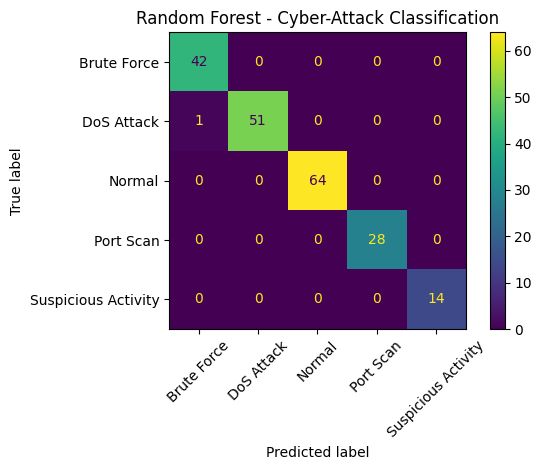


FEATURE IMPORTANCE
                 Feature  Importance
0            Packet_Rate    0.367642
3  Failed_Login_Attempts    0.265935
6       Connection_Count    0.182226
4            Port_Number    0.111411
1            Packet_Size    0.026792
5      Bytes_Transferred    0.024478
2    Connection_Duration    0.021516


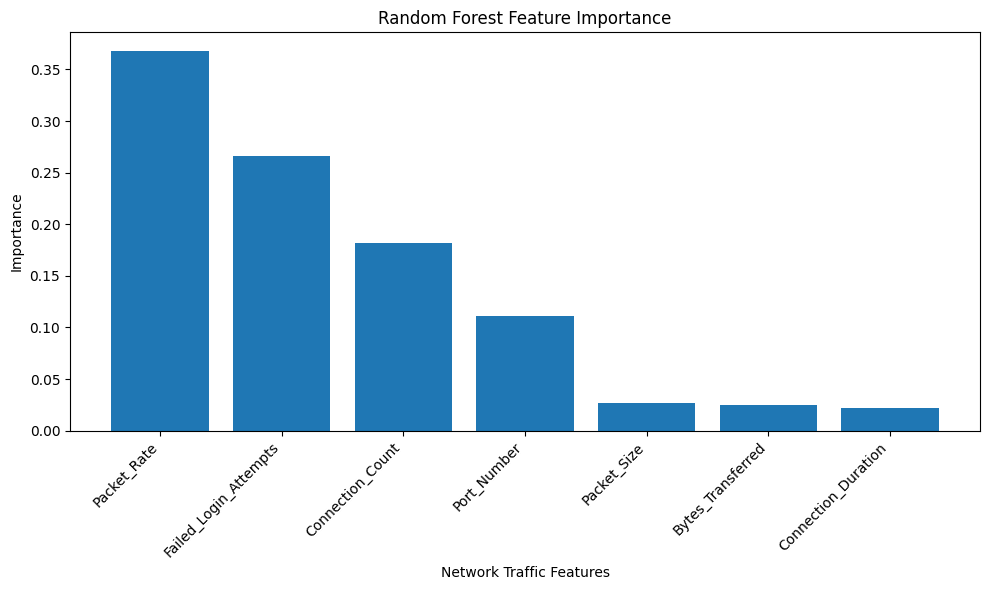


ACTUAL VS PREDICTED RESULTS
     Packet_Rate  Packet_Size  Connection_Duration  Failed_Login_Attempts  \
53           576          806                  228                      4   
800          900          744                   54                      6   
253          234          763                  223                      7   
124          197          684                   87                      3   
878          229         1314                   90                      1   
606          402          114                   92                      9   
784          464          416                  144                      3   
350          962          556                  156                      3   
546          843          983                   95                      6   
769          605          798                  184                      9   
928          424          402                  184                      4   
580           56          753                  

In [10]:
# ============================================================
# EXPERIMENT: IMPLEMENT RANDOM FOREST TO CLASSIFY CYBER-ATTACKS
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. CREATE CYBERSECURITY DATASET
# ============================================================

np.random.seed(42)

number_of_samples = 1000

data = pd.DataFrame({
    "Packet_Rate": np.random.randint(10, 1000, number_of_samples),
    "Packet_Size": np.random.randint(40, 1500, number_of_samples),
    "Connection_Duration": np.random.randint(1, 300, number_of_samples),
    "Failed_Login_Attempts": np.random.randint(0, 10, number_of_samples),
    "Port_Number": np.random.randint(20, 10000, number_of_samples),
    "Bytes_Transferred": np.random.randint(100, 1000000, number_of_samples),
    "Connection_Count": np.random.randint(1, 200, number_of_samples)
})


# ============================================================
# 3. CREATE CYBER-ATTACK LABELS
# ============================================================

def classify_attack(row):

    if row["Packet_Rate"] > 750:
        return "DoS Attack"

    elif row["Failed_Login_Attempts"] >= 7:
        return "Brute Force"

    elif row["Connection_Count"] > 150:
        return "Port Scan"

    elif row["Port_Number"] > 8000:
        return "Suspicious Activity"

    else:
        return "Normal"


data["Attack_Type"] = data.apply(
    classify_attack,
    axis=1
)


# ============================================================
# 4. DISPLAY DATASET
# ============================================================

print("=" * 60)
print("CYBER-ATTACK CLASSIFICATION USING RANDOM FOREST")
print("=" * 60)

print("\nFirst 10 Records:")
print(data.head(10))

print("\nDataset Shape:")
print(data.shape)

print("\nAttack Type Distribution:")
print(data["Attack_Type"].value_counts())


# ============================================================
# 5. SEPARATE FEATURES AND TARGET
# ============================================================

X = data.drop(
    "Attack_Type",
    axis=1
)

y = data["Attack_Type"]


# ============================================================
# 6. SPLIT DATASET INTO TRAINING AND TESTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))


# ============================================================
# 7. CREATE RANDOM FOREST CLASSIFIER
# ============================================================

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 8. TRAIN THE MODEL
# ============================================================

print("\nTraining Random Forest Model...")

model.fit(
    X_train,
    y_train
)

print("Model Training Completed!")


# ============================================================
# 9. MAKE PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 10. CALCULATE ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print(
    "\nAccuracy: {:.2f}%".format(
        accuracy * 100
    )
)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

print("\nConfusion Matrix:")
print(cm)


# ============================================================
# 13. DISPLAY CONFUSION MATRIX GRAPH
# ============================================================

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Random Forest - Cyber-Attack Classification"
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(feature_importance)


# ============================================================
# 15. FEATURE IMPORTANCE GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel(
    "Network Traffic Features"
)

plt.ylabel(
    "Importance"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. ACTUAL VS PREDICTED RESULTS
# ============================================================

results = X_test.copy()

results["Actual_Attack"] = y_test.values

results["Predicted_Attack"] = y_pred

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED RESULTS")
print("=" * 60)

print(
    results.head(15)
)


# ============================================================
# 17. PREDICT A NEW NETWORK TRAFFIC RECORD
# ============================================================

new_network_traffic = pd.DataFrame({
    "Packet_Rate": [900],
    "Packet_Size": [1200],
    "Connection_Duration": [50],
    "Failed_Login_Attempts": [2],
    "Port_Number": [443],
    "Bytes_Transferred": [500000],
    "Connection_Count": [180]
})


# ============================================================
# 18. PREDICT ATTACK TYPE
# ============================================================

new_prediction = model.predict(
    new_network_traffic
)

print("\n" + "=" * 60)
print("NEW NETWORK TRAFFIC PREDICTION")
print("=" * 60)

print(
    "Predicted Attack Type:",
    new_prediction[0]
)


# ============================================================
# 19. PREDICTION PROBABILITY
# ============================================================

prediction_probability = model.predict_proba(
    new_network_traffic
)

probability_table = pd.DataFrame(
    prediction_probability,
    columns=model.classes_
)

print("\nPrediction Probability:")

print(
    probability_table
)


# ============================================================
# 20. FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 60)

print(
    "\nRandom Forest Accuracy: {:.2f}%".format(
        accuracy * 100
    )
)

print(
    "\nThe Random Forest model successfully classified "
    "network traffic into different cyber-attack categories."
)